# Tox21 × JUMP: a Cell Painting pilot

Linking compound identities

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize

RDLogger.DisableLog("rdApp.*") #otherwise: log-line for every molecule
largest_fragment = rdMolStandardize.LargestFragmentChooser() #keeps biggest piece -> strips salts/counter-ions

In [2]:
tox = pd.read_csv("https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/tox21.csv.gz")
labelled = tox[tox["SR-MMP"].notna()].copy() #not every compound was tested in every assay -> NaN

print(len(tox), "records")
print(len(labelled), "with SR-MMP label")
print(labelled["SR-MMP"].mean(), "active") #column contains only 0/1 -> mean is fraction of active compounds

8014 records
5920 with SR-MMP label
0.1581081081081081 active


In [3]:
def get_inchikey(smiles):
    if not isinstance(smiles, str):  #NaN is a float, not a string
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:                  #rdkit can't read the smiles
        return None
    return Chem.MolToInchiKey(largest_fragment.choose(mol))

labelled["inchikey"] = labelled["smiles"].apply(get_inchikey) 
print(labelled["inchikey"].isna().sum(), "not parseable")

labelled = labelled.dropna(subset=["inchikey"]).copy() #drop the 6 unreadable ones
print(len(labelled), "records with key")

6 not parseable
5914 records with key


In [4]:
conflicts = (labelled.groupby("inchikey")["SR-MMP"].nunique() > 1).sum() #nunique > 1 -> same compound has both 0 and 1
compounds = labelled.groupby("inchikey", as_index=False)["SR-MMP"].max() #duplicates would end up in train AND test in phase 2 -> leakage

print(len(compounds), "unique compounds")
print(len(labelled) - len(compounds), "duplicates removed")
print(conflicts, "duplicates with conflicting labels")
print(compounds["SR-MMP"].sum(), "active")

5730 unique compounds
184 duplicates removed
10 duplicates with conflicting labels
912.0 active


In [5]:
jump = pd.read_csv("https://raw.githubusercontent.com/jump-cellpainting/datasets/main/metadata/compound.csv.gz")

jump_keys = set(jump["Metadata_InChIKey"].dropna()) #set -> faster
jump_blocks = {k.split("-")[0] for k in jump_keys}
compounds["block"] = compounds["inchikey"].str.split("-").str[0] #block 1 = skeleton only, ignores stereo + protonation

match_full = compounds["inchikey"].isin(jump_keys)
match_block = compounds["block"].isin(jump_blocks)

print(len(jump_keys), "JUMP compounds")
print(match_full.sum(), "matched on full key")
print(match_block.sum(), "matched on first block")

115795 JUMP compounds
1050 matched on full key
1625 matched on first block


In [6]:
jump_std = jump[jump["Metadata_SMILES"].notna()].copy()
jump_std["std_key"] = jump_std["Metadata_SMILES"].apply(get_inchikey) # same standardisation as the Tox21 side, for every JUMP entry
jump_std = jump_std.dropna(subset=["std_key"])

jump_keys_std = set(jump_std["std_key"]) | jump_keys
jump_blocks_std = {k.split("-")[0] for k in jump_keys_std}

match_full_std = compounds["inchikey"].isin(jump_keys_std)
match_block_std = compounds["block"].isin(jump_blocks_std)

changed = (jump_std["std_key"].str.split("-").str[0] != jump_std["Metadata_InChIKey"].str.split("-").str[0]).sum()
print(changed, "JUMP entries whose first block changes when salts are stripped")
print(match_block_std.sum() - match_block.sum(), "extra block matches after de-salting")
print(match_full_std.sum() - match_full.sum(), "extra full matches after de-salting")
print(jump["Metadata_SMILES"].str.contains(".", regex=False).sum(), "JUMP smiles with more than one fragment") # 0 -> JUMP is already de-salted

3 JUMP entries whose first block changes when salts are stripped
0 extra block matches after de-salting
0 extra full matches after de-salting
0 JUMP smiles with more than one fragment


In [7]:
from collections import defaultdict

jump_by_block = defaultdict(set)              # block 1 -> all JUMP keys with this skeleton
for k in jump_keys_std:
    jump_by_block[k.split("-")[0]].add(k)

def classify(key):
    b1, b2, b3 = key.split("-")
    others = jump_by_block[b1]                # every JUMP entry with the same skeleton
    if any(o.split("-")[1] == b2 for o in others):
        return "same stereo layer, protonation differs"
    if b2 == "UHFFFAOYSA":
        return "JUMP specifies stereo, Tox21 does not"
    if any(o.split("-")[1] == "UHFFFAOYSA" for o in others):
        return "Tox21 specifies stereo, JUMP does not"
    return "both specify stereo, but different"

gap = compounds[match_block & ~match_full_std].copy()
gap["reason"] = gap["inchikey"].apply(classify)

print(len(gap), "in the gap")
print(gap["reason"].value_counts())

575 in the gap
reason
Tox21 specifies stereo, JUMP does not     519
same stereo layer, protonation differs     56
Name: count, dtype: int64


first guess was salts -> wrong, see above

In [8]:
matched = compounds[match_block]
print(matched["SR-MMP"].value_counts())
print(compounds["SR-MMP"].mean(), "active overall")
print(matched["SR-MMP"].mean(), "active in matched subset") #matched subset not enriched in actives

SR-MMP
0.0    1385
1.0     240
Name: count, dtype: int64
0.15916230366492146 active overall
0.1476923076923077 active in matched subset


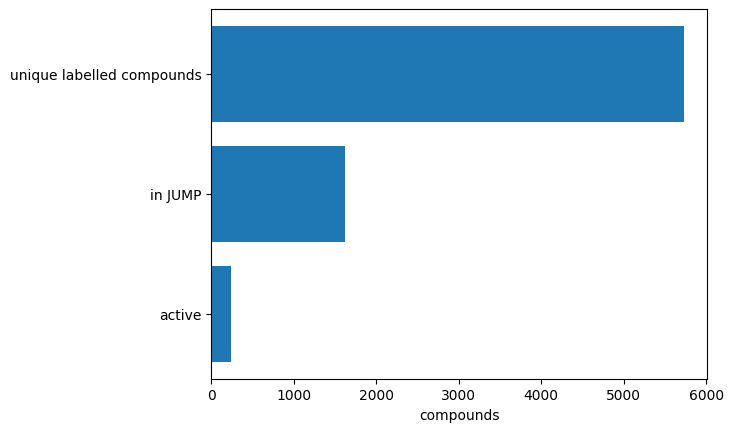

In [9]:
plt.barh(["unique labelled compounds", "in JUMP", "active"],
         [len(compounds), match_block.sum(), matched["SR-MMP"].sum()])
plt.gca().invert_yaxis() #biggest bar on top
plt.xlabel("compounds")
plt.show()